# Main 06 — spatial replication

Quantify TRD1–TRD2 spatial replication for 26 regional, 168 connectivity, and 26 MwC features.

- Formal analysis universe: 12 cortical + 14 limbic ROIs (26 nodes)
- Cross-network connectivity: 12 × 14 = 168 edges
- Pipeline: `main`; step 6 of 10
- Run mode: standalone; all prerequisite steps load automatically in the same kernel.


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)
_run_step("main_01_setup_load.py")
_run_step("main_02_demographics_hc_reference.py")
_run_step("main_03_baseline_discovery_sensitivity.py")
_run_step("main_04_longitudinal_paired_clinical.py")
_run_step("main_05_interactions_mwc.py")


MetaFL package root: .
Main-analysis output root: ./outputs/main_analyses
Cortical IDs: [3, 4, 5, 6, 19, 20, 21, 22, 25, 26, 31, 32]
Limbic IDs: [41, 42, 43, 44, 45, 46, 75, 76, 77, 78, 79, 80, 151, 152]
Cross-edge family: 168


,cohort,clinical_n,ses01_complete_n
0,HC,23,23
1,nTRD,25,25
2,TRD1,35,35
3,TRD2,86,86


,cohort,baseline_n,metric
0,nTRD,25,age/sex-adjusted normative-SC MwC deviation z
1,TRD1,35,age/sex-adjusted normative-SC MwC deviation z
2,TRD2,86,age/sex-adjusted normative-SC MwC deviation z


Written: ./outputs/main_analyses/demographic_and_clinical_summary.xlsx


,variable,HC,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Age,50.91 (17.04); n=23,52.32 (12.22); n=25,48.20 (15.52); n=35,38.44 (14.35); n=86,"one-way ANOVA: HC, nTRD, TRD1",0.561396,Welch t-test,0.002190
1,"Female, n (%)",14 (60.87%); n=23,14 (56.00%); n=25,25 (71.43%); n=35,54 (62.79%); n=86,"Pearson chi-square: HC, nTRD, TRD1",0.443311,Fisher exact test,0.406397
2,Education,14.17 (3.46); n=23,13.44 (3.86); n=25,13.14 (3.83); n=35,14.48 (2.95); n=86,"one-way ANOVA: HC, nTRD, TRD1",0.587829,Welch t-test,0.070156


...

,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,31,15,0,0,0,0,0
1,rTMS,28,13,0,2,0,0,0
2,sham,27,3,0,0,3,0,0


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,31,0.299379,-0.127256,-0.426636,-0.750761,-0.102511,-0.482812,-2.688181,0.011610,27,0.019255,0.102860,0.083605,-0.248743,0.415953,0.099513,0.517087,0.609467,-0.508918,-0.973487,-0.044348,-2.196267,-0.286358,54.0,0.032387,58,0.954648,2.987233e-02,0.950706,0.406628
1,iTBS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,31,-0.589434,0.156725,0.746159,0.195418,1.296901,0.496954,2.766924,0.009597,27,-0.347504,-0.680726,-0.333222,-1.375872,0.709429,-0.126426,-0.656928,0.517000,1.039511,-0.084389,2.163411,1.854341,0.244674,54.0,0.069155,58,0.812377,3.958649e-07,0.369488,0.406628
2,iTBS,edge,AAL3_031_OFClat_L,AAL3_041_Hippocampus_L,31,-0.194847,-0.482488,-0.287641,-0.450633,-0.124648,-0.647316,-3.604102,0.001119,27,-0.406321,-0.366112,0.040208,-0.364814,0.445230,0.039272,0.204061,0.839895,-0.346509,-0.753137,0.060119,-1.708464,-0.226453,54.0,0.093293,58,0.884193,4.821203e-05,0.079765,0.406628
3,iTBS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,31,-1.223280,-0.559661,0.663619,0.122167,1.205071,0.449564,2.503068,0.017987,27,-1.048652,-1.193211,-0.144560,-1.034357,0.745238,-0.064268,-0.333948,0.741097,0.739679,-0.241388,1.720746,1.511586,0.201482,54.0,0.136470,58,0.836800,1.764104e-06,0.232080,0.406628
4,iTBS,edge,AAL3_032_OFClat_R,AAL3_041_Hippocampus_L,31,-0.324582,-0.620665,-0.296083,-0.520207,-0.071959,-0.484571,-2.697975,0.011340,27,-0.575668,-0.532912,0.042756,-0.434471,0.519983,0.035442,0.184159,0.855317,-0.358616,-0.858714,0.141481,-1.437684,-0.192004,54.0,0.156294,58,0.880251,3.572451e-05,0.188284,0.406628
5,iTBS,edge,AAL3_020_Frontal_Sup_Medial_R,AAL3_151_ACC_sub_L,31,-0.739533,-1.365939,-0.626407,-1.164504,-0.088310,-0.427001,-2.377440,0.024008,27,-1.781773,-1.614228,0.167545,-0.926818,1.261909,0.060564,0.314699,0.755502,-0.818398,-1.977522,0.340726,-1.415543,-0.189154,54.0,0.162651,58,0.910501,4.113356e-04,0.051122,0.406628
6,iTBS,edge,AAL3_025_OFCmed_L,AAL3_043_ParaHippocampal_L,31,-0.280652,-0.650436,-0.369783,-0.723282,-0.016285,-0.383701,-2.136355,0.040926,27,-0.525913,-0.571765,-0.045853,-0.387089,0.295384,-0.053156,-0.276205,0.784574,-0.314567,-0.806997,0.177864,-1.280726,-0.171697,54.0,0.205763,58,0.911380,4.439823e-04,0.816547,0.440922
7,iTBS,edge,AAL3_019_Frontal_Sup_Medial_L,AAL3_043_ParaHippocampal_L,31,-0.281879,-0.642525,-0.360646,-0.640456,-0.080836,-0.472772,-2.632281,0.013270,27,-0.855548,-0.913982,-0.058434,-0.579595,0.462728,-0.044354,-0.230470,0.819530,-0.280646,-0.846028,0.284737,-0.995186,-0.134203,54.0,0.324084,58,0.906311,2.871578e-04,0.229800,0.526651
8,iTBS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_043_ParaHippocampal_L,31,-0.214279,-0.693165,-0.478886,-0.873582,-0.084190,-0.445043,-2.477894,0.019069,27,-0.802536,-0.887999,-0.085463,-0.736892,0.565965,-0.051898,-0.269672,0.789541,-0.361774,-1.092450,0.368902,-0.992660,-0.133868,54.0,0.325303,58,0.922173,1.165608e-03,0.345421,0.526651
9,iTBS,edge,AAL3_003_Frontal_Sup_2_L,AAL3_043_ParaHippocampal_L,31,-0.333037,-0.781479,-0.448442,-0.824295,-0.072590,-0.437645,-2.436703,0.020969,27,-1.005109,-1.094027,-0.088917,-0.740008,0.562174,-0.054024,-0.280717,0.781149,-0.339707,-1.063790,0.384377,-0.940597,-0.126963,54.0,0.351100,58,0.876480,2.694182e-05,0.394869,0.526651


                      analysis  arm                       family  tested  nominal_p_lt_0p05  fdr_q_lt_0p05                                                                                         method
         baseline TRD1 vs nTRD TRD1               26 MwC targets      26                  8              0                                                                             HC3 OLS; age + sex
               paired pre-post iTBS               26 MwC targets      26                  1              0                                                                       paired t; post minus pre
               paired pre-post rTMS               26 MwC targets      26                  2              0                                                                       paired t; post minus pre
               paired pre-post sham               26 MwC targets      26                  4              0                                                                       paired t; post 

,modality


,modality,arm,paired_node_index,paired_network,paired_AAL3_ID,ROI,display_roi,paired_n_paired,paired_pre_mean_deviation_HC_z,paired_pre_SD_deviation_HC_z,paired_post_mean_deviation_HC_z,paired_post_SD_deviation_HC_z,paired_post_minus_pre_HC_z,paired_change_ci95_low,paired_change_ci95_high,paired_paired_t,paired_paired_df,paired_effect_size_Cohen_dz,paired_paired_p_uncorrected,paired_change_shapiro_W,...,interaction_covariates,interaction_model,interaction_interaction_q_fdr_BH_26_nodes,interaction_interaction_nominal_p_lt_0p05,interaction_interaction_fdr_q_lt_0p05,HDRS_node_index,HDRS_network,HDRS_AAL3_ID,HDRS_n_used,HDRS_HDRS_improvement_definition,HDRS_MwC_change_definition,HDRS_partial_Spearman_r,HDRS_partial_Spearman_p_uncorrected,HDRS_covariates,HDRS_paired_p_uncorrected,HDRS_paired_nominal_p_lt_0p05,HDRS_partial_Spearman_q_fdr_BH_26_nodes,HDRS_HDRS_nominal_p_lt_0p05,HDRS_HDRS_fdr_q_lt_0p05,HDRS_paired_and_HDRS_nominal_p_lt_0p05
0,MwC,iTBS,16,limbic,44,ParaHippocampal_R,PHG-R,31,0.389801,1.257958,-0.166694,0.842952,-0.556495,-1.019284,-0.093705,-2.455791,30,-0.441073,0.020068,0.981762,...,age + sex,HC3 OLS on post-minus-pre change; equivalent g...,0.324298,False,False,16,limbic,44,31,pre minus post; positive means clinical improv...,post minus pre HC-referenced deviation z,-0.028743,0.882335,age + sex,0.020068,True,0.966008,False,False,False
1,MwC,rTMS,12,cortical,32,OFClat_R,OFClat-R,28,-0.868296,1.029519,-0.244359,1.289997,0.623937,0.151418,1.096455,2.709338,27,0.512017,0.011564,0.972958,...,age + sex,HC3 OLS on post-minus-pre change; equivalent g...,0.251226,True,False,12,cortical,32,28,pre minus post; positive means clinical improv...,post minus pre HC-referenced deviation z,-0.167835,0.412478,age + sex,0.011564,True,0.958074,False,False,False
2,MwC,rTMS,15,limbic,43,ParaHippocampal_L,PHG-L,28,-0.168325,1.028518,0.361014,1.162574,0.529338,0.006234,1.052443,2.076281,27,0.392380,0.047514,0.984907,...,age + sex,HC3 OLS on post-minus-pre change; equivalent g...,0.453343,False,False,15,limbic,43,28,pre minus post; positive means clinical improv...,post minus pre HC-referenced deviation z,0.408485,0.038284,age + sex,0.047514,True,0.574443,True,False,True


## Preamble


In [2]:
"""Auto-extracted pipeline step: Main 06 — spatial replication and integrated report.

Do not edit generated copies independently of the source notebooks.
"""


'Auto-extracted pipeline step: Main 06 — spatial replication and integrated report.\n\nDo not edit generated copies independently of the source notebooks.\n'

## Source 27


In [3]:
import itertools
import math

from matplotlib.patches import Rectangle
from scipy.stats import pearsonr

SPATIAL_OUT = OUTPUT_ROOT / "03_TRD1_TRD2_spatial_correlation"
SPATIAL_OUT.mkdir(parents=True, exist_ok=True)
FIGURE_OUT = OUTPUT_ROOT / "04_figures"
FIGURE_OUT.mkdir(parents=True, exist_ok=True)
N_SPATIAL_PERMUTATIONS = 100_000
SPATIAL_SEED = 20260821
SPATIAL_PERMUTATION_SEED = 20260830
SPATIAL_ALPHA = 0.05
PERMUTATION_BATCH_SIZE = 1_000


def rowwise_pearson(x, y):
    x_centered = x - x.mean(axis=1, keepdims=True)
    y_centered = y - y.mean(axis=1, keepdims=True)
    numerator = np.sum(x_centered * y_centered, axis=1)
    denominator = np.sqrt(np.sum(x_centered**2, axis=1) * np.sum(y_centered**2, axis=1))
    return np.divide(
        numerator, denominator,
        out=np.full_like(numerator, np.nan, dtype=float), where=denominator > 0,
    )


def spatial_point_metrics(first, second):
    pearson = pearsonr(first, second)
    same = ((first > 0) & (second > 0)) | ((first < 0) & (second < 0))
    abs_first, abs_second = np.abs(first), np.abs(second)
    weighted_signed_dsc = (
        2 * np.sum(np.minimum(abs_first, abs_second) * same)
        / (abs_first.sum() + abs_second.sum())
    )
    return {
        "pearson_r": float(pearson.statistic),
        "pearson_p": float(pearson.pvalue),
        "same_direction_proportion": float(same.mean()),
        "same_direction_count": int(same.sum()),
        "weighted_signed_dsc": float(weighted_signed_dsc),
    }


def permutation_metric_batch(first, permuted_second):
    first_rows = np.broadcast_to(first, permuted_second.shape)
    same = ((first_rows > 0) & (permuted_second > 0)) | (
        (first_rows < 0) & (permuted_second < 0)
    )
    abs_first, abs_second = np.abs(first_rows), np.abs(permuted_second)
    return pd.DataFrame({
        "pearson_r": rowwise_pearson(first_rows, permuted_second),
        "same_direction_proportion": same.mean(axis=1),
        "weighted_signed_dsc": (
            2 * (np.minimum(abs_first, abs_second) * same).sum(axis=1)
            / (abs_first.sum(axis=1) + abs_second.sum(axis=1))
        ),
    })


def expand_bilateral_pair_permutations(pair_permutations, pair_offset=0):
    pair_permutations = np.asarray(pair_permutations, dtype=int)
    hemispheres = np.array([0, 1], dtype=int)
    return (2 * pair_permutations[..., :, None] + hemispheres + pair_offset).reshape(
        len(pair_permutations), -1
    )


def regional_pair_permutation_null(first, second, n_permutations, rng):
    """Permute 13 bilateral ROI identities while preserving left/right pairing."""
    chunks, completed = [], 0
    n_pairs = len(second) // 2
    assert n_pairs == 13 and len(second) == 26
    while completed < n_permutations:
        size = min(PERMUTATION_BATCH_SIZE, n_permutations - completed)
        pair_orders = np.argsort(rng.random((size, n_pairs)), axis=1)
        feature_orders = expand_bilateral_pair_permutations(pair_orders)
        metrics = permutation_metric_batch(first, second[feature_orders])
        metrics.insert(0, "permutation_iteration", np.arange(completed + 1, completed + size + 1))
        chunks.append(metrics)
        completed += size
    return pd.concat(chunks, ignore_index=True)


def connectivity_endpoint_permutation_null(first, second):
    """Exactly permute six frontal and seven limbic bilateral endpoint pairs."""
    first = np.asarray(first, dtype=float)
    second_matrix = np.asarray(second, dtype=float).reshape(12, 14)
    row_pair_orders = np.asarray(list(itertools.permutations(range(6))), dtype=np.int16)
    column_pair_orders = np.asarray(list(itertools.permutations(range(7))), dtype=np.int16)
    row_endpoint_orders = expand_bilateral_pair_permutations(row_pair_orders)
    column_endpoint_orders = expand_bilateral_pair_permutations(column_pair_orders)
    chunks, completed = [], 0
    for row_order in row_endpoint_orders:
        row_reordered = second_matrix[row_order, :]
        permuted = np.transpose(row_reordered[:, column_endpoint_orders], (1, 0, 2)).reshape(
            len(column_endpoint_orders), -1
        )
        metrics = permutation_metric_batch(first, permuted)
        metrics.insert(0, "permutation_iteration", np.arange(completed + 1, completed + len(metrics) + 1))
        chunks.append(metrics)
        completed += len(metrics)
    result = pd.concat(chunks, ignore_index=True)
    assert len(result) == math.factorial(6) * math.factorial(7)
    return result


def empirical_upper_tail_p(null_values, observed, exact):
    null_values = np.asarray(null_values, dtype=float)
    offset = 0 if exact else 1
    return float((np.count_nonzero(null_values >= observed) + offset) / (len(null_values) + offset))


def upper_tail_significance_threshold(null_values, alpha, exact):
    ordered = np.sort(np.asarray(null_values, dtype=float))
    support, first_indices = np.unique(ordered, return_index=True)
    offset = 0 if exact else 1
    upper_tail_p = (len(ordered) - first_indices + offset) / (len(ordered) + offset)
    eligible = support[upper_tail_p < alpha]
    return float(eligible[0]) if len(eligible) else np.nan


# Scientific sequential palettes progress from light to dark across the three panels.
# Blues: ColorBrewer Blues; orange-yellow: colorblind-safe sequential Oranges.
SPATIAL_BLUE_SEQUENCE = ["#6BAED6", "#3182BD", "#08519C"]
SPATIAL_ORANGE_SEQUENCE = ["#FDB863", "#E69F00", "#B35806"]
modalities = {
    "Regional": {
        "display_name": "Regional SUVR",
        "labels": pd.DataFrame({"ROI": ROI_COLUMNS}),
        "trd1": trd1_result["case_regional"].to_numpy(float),
        "trd2": trd2_context["case_regional"].to_numpy(float),
        "color": SPATIAL_BLUE_SEQUENCE[0], "agreement_color": SPATIAL_ORANGE_SEQUENCE[0], "unit": "ROIs",
    },
    "Connectivity": {
        "display_name": "Metabolic edge",
        "labels": pd.DataFrame({
            "ROI_1": [edge[0] for edge in CROSS_EDGE_NAMES],
            "ROI_2": [edge[1] for edge in CROSS_EDGE_NAMES],
        }),
        "trd1": trd1_result["case_edge"],
        "trd2": trd2_context["case_edge"],
        "color": SPATIAL_BLUE_SEQUENCE[1], "agreement_color": SPATIAL_ORANGE_SEQUENCE[1], "unit": "edges",
    },
    "MwC": {
        "display_name": "MwC",
        "labels": pd.DataFrame({"ROI": ROI_COLUMNS}),
        "trd1": mwc_group_values["TRD1"],
        "trd2": mwc_group_values["TRD2"],
        "color": SPATIAL_BLUE_SEQUENCE[2], "agreement_color": SPATIAL_ORANGE_SEQUENCE[2], "unit": "ROIs",
    },
}

summary_rows, permutation_threshold_rows = [], []
spatial_vectors, spatial_permutation_inference = {}, {}
for modality, item in modalities.items():
    mean1, mean2 = np.nanmean(item["trd1"], axis=0), np.nanmean(item["trd2"], axis=0)
    point = spatial_point_metrics(mean1, mean2)
    if modality in {"Regional", "MwC"}:
        permutation_seed = SPATIAL_PERMUTATION_SEED + (1 if modality == "MwC" else 0)
        permutation_null = regional_pair_permutation_null(
            mean1, mean2, N_SPATIAL_PERMUTATIONS, np.random.default_rng(permutation_seed)
        )
        exact_permutation = False
        permutation_scheme = "Monte Carlo permutation of 13 bilateral ROI-pair labels; left/right pairing preserved"
    else:
        permutation_seed = np.nan
        permutation_null = connectivity_endpoint_permutation_null(mean1, mean2)
        exact_permutation = True
        permutation_scheme = "Exact independent permutations of six bilateral frontal and seven bilateral limbic node-pair labels"

    np.savez_compressed(
        SPATIAL_OUT / f"{modality.lower()}_structure_preserving_null.npz",
        **{column: permutation_null[column].to_numpy(float) for column in [
            "pearson_r", "same_direction_proportion", "weighted_signed_dsc"
        ]},
    )
    vectors = item["labels"].copy()
    vectors.insert(0, "feature_index", np.arange(1, len(vectors) + 1))
    vectors["TRD1_mean_deviation"] = mean1
    vectors["TRD2_mean_deviation"] = mean2
    vectors["same_direction"] = ((mean1 > 0) & (mean2 > 0)) | ((mean1 < 0) & (mean2 < 0))
    spatial_vectors[modality] = vectors
    spatial_permutation_inference[modality] = {}

    for label, column, p_key in [
        ("Pearson correlation", "pearson_r", "pearson_p"),
        ("Same-direction proportion", "same_direction_proportion", None),
        ("Magnitude-weighted signed DSC", "weighted_signed_dsc", None),
    ]:
        null_values = permutation_null[column].to_numpy(float)
        empirical_p = empirical_upper_tail_p(null_values, point[column], exact_permutation)
        critical_value = upper_tail_significance_threshold(null_values, SPATIAL_ALPHA, exact_permutation)
        inference = {
            "empirical_p_one_sided": empirical_p,
            "null_mean": float(np.mean(null_values)),
            "null_95th_percentile": float(np.quantile(null_values, 0.95, method="higher")),
            "significance_threshold_alpha_0_05": critical_value,
            "threshold_operator": ">=",
            "threshold_exceeded": bool(np.isfinite(critical_value) and point[column] >= critical_value),
            "significant_at_alpha_0_05": bool(empirical_p < SPATIAL_ALPHA),
        }
        spatial_permutation_inference[modality][column] = inference
        summary_rows.append({
            "modality": modality, "display_name": item["display_name"],
            "n_TRD1": len(item["trd1"]), "n_TRD2": len(item["trd2"]),
            "n_features": item["trd1"].shape[1], "metric": label,
            "estimate": point[column],
            "parametric_p_descriptive": np.nan if p_key is None else point[p_key],
            **inference,
            "same_direction_count": point["same_direction_count"] if column == "same_direction_proportion" else np.nan,
            "permutation_resamples": len(permutation_null),
            "permutation_exact": exact_permutation,
            "permutation_seed": permutation_seed,
            "permutation_scheme": permutation_scheme,
        })
        if column in {"same_direction_proportion", "weighted_signed_dsc"}:
            permutation_threshold_rows.append({
                "modality": modality, "metric": label, "estimate": point[column], **inference,
                "critical_same_direction_count": int(round(critical_value * len(mean1)))
                if column == "same_direction_proportion" and np.isfinite(critical_value) else np.nan,
                "critical_same_direction_percent": float(100 * critical_value)
                if column == "same_direction_proportion" and np.isfinite(critical_value) else np.nan,
                "n_features": len(mean1), "alpha": SPATIAL_ALPHA, "alternative": "greater",
                "permutation_resamples": len(permutation_null), "permutation_exact": exact_permutation,
                "permutation_seed": permutation_seed, "permutation_scheme": permutation_scheme,
            })

spatial_summary = pd.DataFrame(summary_rows)
spatial_permutation_thresholds = pd.DataFrame(permutation_threshold_rows)
assert len(spatial_permutation_thresholds) == 6
assert spatial_permutation_thresholds["empirical_p_one_sided"].between(0, 1).all()
spatial_summary.to_csv(SPATIAL_OUT / "spatial_correlation_summary.csv", index=False)
spatial_permutation_thresholds.to_csv(SPATIAL_OUT / "spatial_similarity_permutation_thresholds.csv", index=False)
spatial_vectors["Regional"].to_csv(SPATIAL_OUT / "regional_mean_deviation_vectors.csv", index=False)
spatial_vectors["Connectivity"].to_csv(SPATIAL_OUT / "connectivity_mean_deviation_vectors.csv", index=False)
spatial_vectors["MwC"].to_csv(SPATIAL_OUT / "mwc_mean_deviation_vectors.csv", index=False)

figure_dsc_rows = []
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3), constrained_layout=False)
fig.patch.set_facecolor("white")
for ax, (modality, item) in zip(axes, modalities.items()):
    x, y = np.nanmean(item["trd1"], axis=0), np.nanmean(item["trd2"], axis=0)
    point = spatial_point_metrics(x, y)
    p = spatial_permutation_inference[modality]["pearson_r"]["empirical_p_one_sided"]
    if p < 0.001:
        p_text, stars = "< 0.001", "***"
    elif p < 0.01:
        p_text, stars = f"= {p:.3f}", "**"
    elif p < 0.05:
        p_text, stars = f"= {p:.3f}", "*"
    else:
        p_text, stars = f"= {p:.3f}", ""
    sns.regplot(
        x=x, y=y, ax=ax, ci=95, n_boot=1000, seed=SPATIAL_SEED,
        color=item["color"], scatter_kws={"s": 14, "alpha": 0.8, "edgecolor": "none"},
        line_kws={"lw": 1.5},
    )
    ax.set_title(item["display_name"], fontsize=15, fontweight="bold", pad=8)
    ax.text(0.03, 0.95, f"r = {point['pearson_r']:.3f},  p {p_text}{stars}",
            transform=ax.transAxes, ha="left", va="top", fontsize=14, fontweight="bold")
    ax.text(0.03, 0.86, rf"$\mathbf{{DSC}}_{{\mathbf{{weighted}}}}$ = {point['weighted_signed_dsc']:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=14, fontweight="bold")
    ax.set_facecolor("white")
    ax.set_box_aspect(1)
    ax.grid(False)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.tick_params(axis="both", labelbottom=False, labelleft=False, length=0)
    for spine in ax.spines.values():
        spine.set_color("#666666")
    proportion, count, feature_n = point["same_direction_proportion"], point["same_direction_count"], len(x)
    inset = ax.inset_axes([0.67, 0.035, 0.30, 0.30])
    inset.set_axis_off(); inset.set_xlim(0, 1); inset.set_ylim(0, 1); inset.patch.set_alpha(0)
    inset.text(0.5, 0.78, f"{100 * proportion:.1f}%", ha="center", va="center",
               fontsize=15, fontweight="bold", color=item["agreement_color"])
    inset.add_patch(Rectangle((0.08, 0.49), 0.84, 0.10, facecolor="#F1E6DA", edgecolor="none"))
    inset.add_patch(Rectangle((0.08, 0.49), 0.84 * proportion, 0.10,
                              facecolor=item["agreement_color"], edgecolor="none"))
    inset.text(0.5, 0.20, f"({count}/{feature_n}\n{item['unit']})", ha="center", va="center",
               fontsize=14, fontweight="medium", linespacing=1.05, color="#333333")
    figure_dsc_rows.append({
        "modality": modality, "pearson_r": point["pearson_r"],
        "pearson_p_descriptive": point["pearson_p"], "pearson_p_empirical_one_sided": p,
        "DSC_weighted": point["weighted_signed_dsc"],
        "DSC_weighted_p_empirical_one_sided": spatial_permutation_inference[modality]["weighted_signed_dsc"]["empirical_p_one_sided"],
        "same_direction_n": count, "feature_n": feature_n,
        "same_direction_percent": 100 * proportion,
        "same_direction_p_empirical_one_sided": spatial_permutation_inference[modality]["same_direction_proportion"]["empirical_p_one_sided"],
    })

fig.subplots_adjust(left=0.01, right=0.995, top=0.90, bottom=0.03, wspace=0.04)
spatial_png = FIGURE_OUT / "spatial_correlation_scatter.png"
spatial_pdf = FIGURE_OUT / "spatial_correlation_scatter.pdf"
fig.savefig(spatial_png, dpi=600, facecolor="white")
fig.savefig(spatial_pdf, dpi=600, facecolor="white")
plt.close(fig)
pd.DataFrame(figure_dsc_rows).to_csv(SPATIAL_OUT / "spatial_correlation_figure_DSC_values.csv", index=False)
display(spatial_summary)
display(spatial_permutation_thresholds)


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,86,26,Pearson correlation,0.975947,2.189280e-17,9.999900e-06,0.001378,0.464438,0.464511,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,86,26,Same-direction proportion,0.884615,NaN,1.249988e-03,0.494524,0.730769,0.807692,>=,True,True,23.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,86,26,Magnitude-weighted signed DSC,0.705787,NaN,9.999900e-06,0.286159,0.462058,0.462071,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,86,168,Pearson correlation,0.736788,5.082956e-30,5.511464e-07,0.017604,0.225937,0.225937,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,86,168,Same-direction proportion,0.892857,NaN,1.455026e-04,0.793084,0.833333,0.845238,>=,True,True,150.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,86,168,Magnitude-weighted signed DSC,0.756704,NaN,1.653439e-06,0.568389,0.618378,0.618378,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,86,26,Pearson correlation,0.956093,2.705797e-14,9.999900e-06,0.027478,0.438663,0.438706,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,86,26,Same-direction proportion,0.884615,NaN,8.899911e-04,0.553074,0.730769,0.807692,>=,True,True,23.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,86,26,Magnitude-weighted signed DSC,0.803910,NaN,9.999900e-06,0.376908,0.526015,0.526018,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


,modality,metric,estimate,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,critical_same_direction_count,critical_same_direction_percent,n_features,alpha,alternative,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Same-direction proportion,0.884615,0.001250,0.494524,0.730769,0.807692,>=,True,True,21.0,80.769231,26,0.05,greater,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Magnitude-weighted signed DSC,0.705787,0.000010,0.286159,0.462058,0.462071,>=,True,True,NaN,NaN,26,0.05,greater,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Connectivity,Same-direction proportion,0.892857,0.000146,0.793084,0.833333,0.845238,>=,True,True,142.0,84.523810,168,0.05,greater,3628800,True,NaN,Exact independent permutations of six bilatera...
3,Connectivity,Magnitude-weighted signed DSC,0.756704,0.000002,0.568389,0.618378,0.618378,>=,True,True,NaN,NaN,168,0.05,greater,3628800,True,NaN,Exact independent permutations of six bilatera...
4,MwC,Same-direction proportion,0.884615,0.000890,0.553074,0.730769,0.807692,>=,True,True,21.0,80.769231,26,0.05,greater,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
5,MwC,Magnitude-weighted signed DSC,0.803910,0.000010,0.376908,0.526015,0.526018,>=,True,True,NaN,NaN,26,0.05,greater,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


## Source 29


In [4]:
summary = pd.DataFrame([
    {"analysis": "TRD1 vs nTRD edge", "family_or_tested_n": 168,
     "reporting_rule": "uncorrected p<0.01", "reported_n": len(trd1_result["edge_reported"])},
    {"analysis": "TRD1 vs nTRD regional", "family_or_tested_n": 26,
     "reporting_rule": "uncorrected p<0.01", "reported_n": len(trd1_result["regional_reported"])},
    {"analysis": "HDRS-adjusted sensitivity edge", "family_or_tested_n": 168,
     "reporting_rule": "uncorrected p<0.01", "reported_n": len(sensitivity_edge_p001)},
    {"analysis": "HDRS-adjusted sensitivity regional", "family_or_tested_n": 26,
     "reporting_rule": "uncorrected p<0.01", "reported_n": len(sensitivity_regional_p001)},
])

for result in [itbs_result, rtms_result, sham_result]:
    for modality in ["edge", "regional"]:
        rows = [{
            "analysis": f"{result['arm']} {modality} pre-post",
            "family_or_tested_n": 168 if modality == "edge" else 26,
            "reporting_rule": "paired uncorrected p<0.05",
            "reported_n": len(result[f"{modality}_selected"]),
        }]
        if result["arm"] != "sham":
            rows.extend([
                {
                    "analysis": f"{result['arm']} {modality} HDRS",
                    "family_or_tested_n": len(result[f"{modality}_hdrs_all"]),
                    "reporting_rule": "BH-FDR q<0.05 primary",
                    "reported_n": len(result[f"{modality}_hdrs_fdr"]),
                },
                {
                    "analysis": f"{result['arm']} {modality} HDRS",
                    "family_or_tested_n": len(result[f"{modality}_hdrs_all"]),
                    "reporting_rule": "uncorrected p<0.05 exploratory",
                    "reported_n": len(result[f"{modality}_hdrs_exploratory"]),
                },
            ])
        summary = pd.concat([summary, pd.DataFrame(rows)], ignore_index=True)

summary = pd.concat([summary, pd.DataFrame([{
    "analysis": "Active treatment vs sham group-by-time",
    "family_or_tested_n": len(interaction_all),
    "reporting_rule": "ordinary OLS uncorrected p<0.05",
    "reported_n": len(interaction_p05),
}])], ignore_index=True)

combined_file = OUTPUT_ROOT / "all_reported_results.xlsx"
with pd.ExcelWriter(combined_file, engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="summary", index=False)
    demographic_table.to_excel(writer, sheet_name="demographic", index=False)
    baseline_hdrs_table.to_excel(writer, sheet_name="baseline_HDRS", index=False)
    msm_table.to_excel(writer, sheet_name="MSM_scores", index=False)
    hdrs_reduction_table.to_excel(writer, sheet_name="HDRS_reduction", index=False)
    stimulation_table.to_excel(writer, sheet_name="stimulation_paired", index=False)
    trd1_result["edge_reported"].to_excel(writer, sheet_name="TRD1_edges_p001", index=False)
    trd1_result["regional_reported"].to_excel(writer, sheet_name="TRD1_regions_p001", index=False)
    sensitivity_summary.to_excel(writer, sheet_name="HDRS_sensitivity_summary", index=False)
    sensitivity_edge_p001.to_excel(writer, sheet_name="HDRS_sens_edge_p001", index=False)
    sensitivity_regional_p001.to_excel(writer, sheet_name="HDRS_sens_region_p001", index=False)
    for result in [itbs_result, rtms_result, sham_result]:
        arm = result["arm"]
        result["edge_selected"].to_excel(writer, sheet_name=f"{arm}_edge_prepost_p05", index=False)
        result["regional_selected"].to_excel(writer, sheet_name=f"{arm}_region_prepost_p05", index=False)
        if arm != "sham":
            result["edge_hdrs_fdr"].to_excel(writer, sheet_name=f"{arm}_edge_HDRS_FDR", index=False)
            result["edge_hdrs_exploratory"].to_excel(writer, sheet_name=f"{arm}_edge_HDRS_p05", index=False)
            result["regional_hdrs_fdr"].to_excel(writer, sheet_name=f"{arm}_region_HDRS_FDR", index=False)
            result["regional_hdrs_exploratory"].to_excel(writer, sheet_name=f"{arm}_region_HDRS_p05", index=False)
    interaction_all.to_excel(writer, sheet_name="active_vs_sham_interaction", index=False)
    spatial_summary.to_excel(writer, sheet_name="TRD1_TRD2_spatial", index=False)
style_excel_workbook(combined_file)
print("Combined workbook:", combined_file)
display(summary)


Combined workbook: ./outputs/main_analyses/all_reported_results.xlsx


,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,19
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,8
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,3
4,iTBS edge pre-post,168,paired uncorrected p<0.05,15
5,iTBS edge HDRS,15,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,15,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


## Results preview

Key numerical tables and figures generated by this step are displayed below. The full-resolution files remain under `outputs/`.


### Key tables

**TRD1-TRD2 spatial replication**  
`outputs/main_analyses/03_TRD1_TRD2_spatial_correlation/spatial_correlation_summary.csv` — 9 rows × 20 columns

,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,86,26,Pearson correlation,0.975947,2.189280e-17,9.999900e-06,0.001378,0.464438,0.464511,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
1,Regional,Regional SUVR,35,86,26,Same-direction proportion,0.884615,NaN,1.249988e-03,0.494524,0.730769,0.807692,>=,True,True,23.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
2,Regional,Regional SUVR,35,86,26,Magnitude-weighted signed DSC,0.705787,NaN,9.999900e-06,0.286159,0.462058,0.462071,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
3,Connectivity,Metabolic edge,35,86,168,Pearson correlation,0.736788,5.082956e-30,5.511464e-07,0.017604,0.225937,0.225937,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
4,Connectivity,Metabolic edge,35,86,168,Same-direction proportion,0.892857,NaN,1.455026e-04,0.793084,0.833333,0.845238,>=,True,True,150.0,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
5,Connectivity,Metabolic edge,35,86,168,Magnitude-weighted signed DSC,0.756704,NaN,1.653439e-06,0.568389,0.618378,0.618378,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
6,MwC,MwC,35,86,26,Pearson correlation,0.956093,2.705797e-14,9.999900e-06,0.027478,0.438663,0.438706,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
7,MwC,MwC,35,86,26,Same-direction proportion,0.884615,NaN,8.899911e-04,0.553074,0.730769,0.807692,>=,True,True,23.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
8,MwC,MwC,35,86,26,Magnitude-weighted signed DSC,0.803910,NaN,9.999900e-06,0.376908,0.526015,0.526018,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...


**Integrated result summary**  
`outputs/main_analyses/all_reported_results.xlsx` — 19 rows × 4 columns

,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,19
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,8
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,3
4,iTBS edge pre-post,168,paired uncorrected p<0.05,15
5,iTBS edge HDRS,15,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,15,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


### Figures

**`outputs/main_analyses/04_figures/spatial_correlation_scatter.png`**

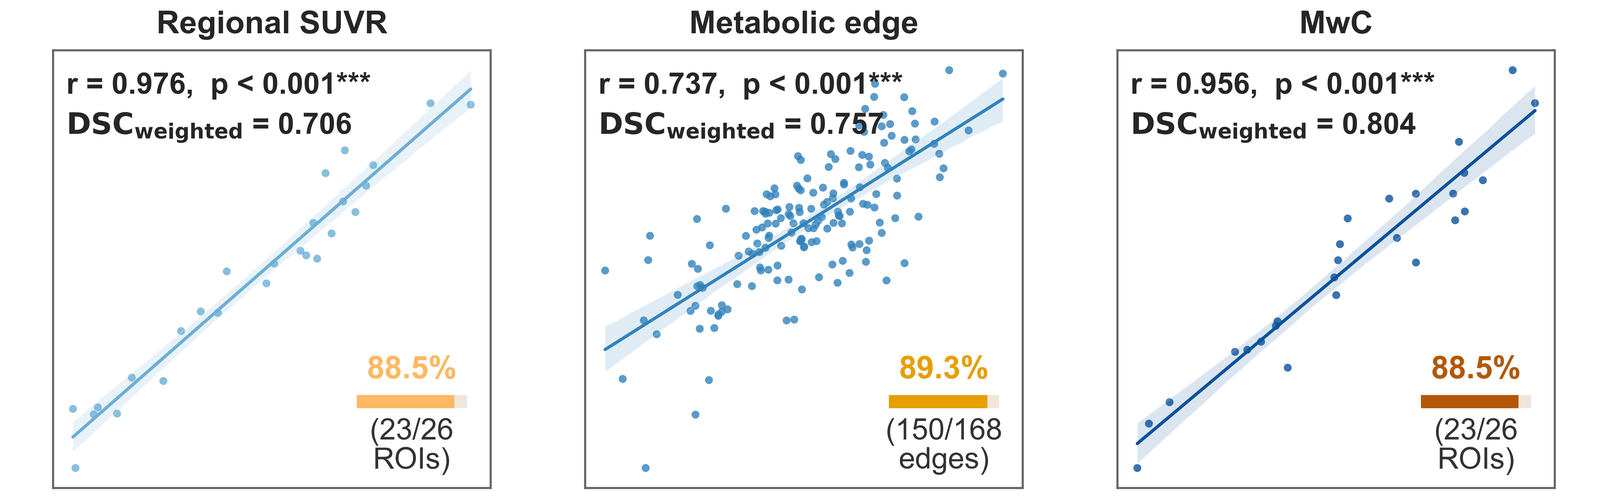

In [5]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'TRD1-TRD2 spatial replication', 'path': 'outputs/main_analyses/03_TRD1_TRD2_spatial_correlation/spatial_correlation_summary.csv'}, {'title': 'Integrated result summary', 'path': 'outputs/main_analyses/all_reported_results.xlsx', 'sheet': 'summary', 'max_rows': 30}]
_inline_figure_paths = ['outputs/main_analyses/04_figures/spatial_correlation_scatter.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
